# Predicting long term movie performance using as few early reviews

## Data Cleaning

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

### Cleaning Movie and Review Data

- Load Horror, Animation, and Adventure movie tables and label each row with its source genre
- Resolve cross-genre duplicates so each movie keeps one preferred genre
- Parse runtime into minutes; clean MPAA rating, release year, and IMDb rating
- Assign an id for each movie
- Load matching review CSVs, drop reviews without a star rating or date
- Clean HTML from review text, order reviews by date within each movie
- Label movies positive if star rating ≥ 7

In [2]:
# load one CSV per genre and tag rows with that genre
movie_frames = []
for genre in ["Horror", "Animation", "Adventure"]:
    df = pd.read_csv(Path("movies_per_genre") / f"{genre}.csv")
    df["genre"] = genre
    movie_frames.append(df)

movies = pd.concat(movie_frames, ignore_index=True)

# prefer the first matching genre that appears if the title appears in more than one genre
def preferred_genre(row):
    tags = [t.strip() for t in str(row["genres"]).split(";") if t.strip()]
    for tag in tags:
        if tag in ["Horror", "Animation", "Adventure"]:
            return tag
    return row["genre"]

movies["genre"] = movies.apply(preferred_genre, axis=1)
movies = movies.drop_duplicates(subset=["name", "year"], keep="first").reset_index(drop=True)
movies.head()

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews,review_url,genre
0,The Shining,1980,R,2h 26min,Drama; Horror;,13 June 1980 (USA),8.4,860290,1805,https://www.imdb.com/title/tt0081505/reviews/_...,Horror
1,Alien,1979,R,1h 57min,Horror; Sci-Fi;,22 June 1979 (USA),8.4,762793,1423,https://www.imdb.com/title/tt0078748/reviews/_...,Horror
2,World War Z,2013,PG-13,1h 56min,Action; Adventure; Horror;,21 June 2013 (USA),7.0,586801,1125,https://www.imdb.com/title/tt0816711/reviews/_...,Adventure
3,Psycho,1960,R,1h 49min,Horror; Mystery; Thriller;,8 September 1960 (USA),8.5,580951,1263,https://www.imdb.com/title/tt0054215/reviews/_...,Horror
4,Shaun of the Dead,2004,R,1h 39min,Comedy; Horror;,24 September 2004 (USA),7.9,499244,971,https://www.imdb.com/title/tt0365748/reviews/_...,Horror


In [3]:
# convert strings like into total minutes
def parse_runtime_minutes(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    hours = re.search(r"(\d+)\s*h", text)
    minutes = re.search(r"(\d+)\s*min", text)
    total = 0
    if hours:
        total += int(hours.group(1)) * 60
    if minutes:
        total += int(minutes.group(1))
    return total if total > 0 else np.nan


# clean and rename metadata columns
movies["movie_id"] = np.arange(len(movies), dtype=int)
movies["runtime"] = movies["run_length"].map(parse_runtime_minutes)
movies["mpaa_rating"] = movies["movie_rated"].astype(str).str.strip()
movies["release_year"] = movies["year"].astype(int)
movies["imdb_rating"] = movies["rating"].astype(float)
movies["num_raters"] = movies["num_raters"].astype(int)
movies["num_reviews_listed"] = movies["num_reviews"].astype(int)

movies.head()

,name,year,movie_rated,run_length,genres,release_date,rating,num_raters,num_reviews,review_url,genre,movie_id,runtime,mpaa_rating,release_year,imdb_rating,num_reviews_listed
0,The Shining,1980,R,2h 26min,Drama; Horror;,13 June 1980 (USA),8.4,860290,1805,https://www.imdb.com/title/tt0081505/reviews/_...,Horror,0,146,R,1980,8.4,1805
1,Alien,1979,R,1h 57min,Horror; Sci-Fi;,22 June 1979 (USA),8.4,762793,1423,https://www.imdb.com/title/tt0078748/reviews/_...,Horror,1,117,R,1979,8.4,1423
2,World War Z,2013,PG-13,1h 56min,Action; Adventure; Horror;,21 June 2013 (USA),7.0,586801,1125,https://www.imdb.com/title/tt0816711/reviews/_...,Adventure,2,116,PG-13,2013,7.0,1125
3,Psycho,1960,R,1h 49min,Horror; Mystery; Thriller;,8 September 1960 (USA),8.5,580951,1263,https://www.imdb.com/title/tt0054215/reviews/_...,Horror,3,109,R,1960,8.5,1263
4,Shaun of the Dead,2004,R,1h 39min,Comedy; Horror;,24 September 2004 (USA),7.9,499244,971,https://www.imdb.com/title/tt0365748/reviews/_...,Horror,4,99,R,2004,7.9,971


In [4]:
# review filenames replace ':' with '_' in the movie title
# so we change it so that we can find the matching csv file
def review_filename(name, year):
    return f"{str(name).replace(':', '_')} {int(year)}.csv"


# clean review text: strip HTML tags and collapse whitespace
def clean_review_text(text):
    if pd.isna(text):
        return ""
    cleaned = re.sub(r"<br\s*/?>", " ", str(text), flags=re.IGNORECASE)
    cleaned = re.sub(r"<[^>]+>", " ", cleaned)
    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    return cleaned


# load each movie's review file and attach movie_id / genre
review_frames = []
for row in movies.itertuples(index=False):
    path = Path("all_reviews_per_movie_raw") / review_filename(row.name, row.release_year)
    if not path.exists():
        continue
    rev = pd.read_csv(path)
    rev["movie_id"] = row.movie_id
    rev["genre"] = row.genre
    review_frames.append(rev)

reviews = pd.concat(review_frames, ignore_index=True)

# drop reviews with missing star rating or date
reviews["star_rating"] = pd.to_numeric(reviews["rating"], errors="coerce")
reviews = reviews.dropna(subset=["star_rating"]).copy()
reviews["star_rating"] = reviews["star_rating"].astype(int)

reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
reviews = reviews.dropna(subset=["date"]).copy()

# clean text and create binary positive label
reviews["text"] = reviews["review"].map(clean_review_text)
reviews = reviews[reviews["text"].str.len() > 0].copy()
reviews["positive"] = (reviews["star_rating"] >= 7).astype(int)

# chronological order within each movie (1 = first review)
reviews = reviews.sort_values(["movie_id", "date", "username"], kind="mergesort")
reviews["review_order"] = reviews.groupby("movie_id").cumcount() + 1

reviews = reviews[
    ["movie_id", "genre", "review_order", "date", "star_rating", "positive", "text"]
].reset_index(drop=True)

# keep only movies that still have at least one usable review
movies = movies[movies["movie_id"].isin(reviews["movie_id"].unique())].reset_index(drop=True)
reviews.head()

,movie_id,genre,review_order,date,star_rating,positive,text
0,0,Horror,1,1998-08-04,10,1,"First of all, I loved the book. It remains my ..."
1,0,Horror,2,1998-08-07,10,1,Although it is sometimes considered to be a mo...
2,0,Horror,3,1998-09-07,10,1,"Stanley Kubrick's ""The Shining"" was a high-wat..."
3,0,Horror,4,1998-10-11,10,1,This is a remarkable milestone in cinema. Kubr...
4,0,Horror,5,1998-10-14,10,1,What can I say to all the fans of the novel Th...


### Train/Validation/Test Split

- Split by movie 
- Stratify on genre: 70% train, then split the remaining 30% into 15% validation / 15% test
- Split train movies in half into `lstm_train` and `mlp_train`
- Add a `split` column on movies and merge it onto reviews by `movie_id`

In [5]:
# 70/30 split stratified by genre
train_movies, temp_movies = train_test_split(
    movies, test_size=0.30, stratify=movies["genre"], random_state=42)

# split 30% in half (15% validation, 15% test)
val_movies, test_movies = train_test_split(
    temp_movies, test_size=0.50, stratify=temp_movies["genre"], random_state=42)

# split train in half: one half for LSTM and the other half for MLP
lstm_train_movies, mlp_train_movies = train_test_split(
    train_movies, test_size=0.50, stratify=train_movies["genre"], random_state=42)

# create column identifying which split each movie belongs to
movies = movies.copy()
movies["split"] = None
for subset, label in [
    (lstm_train_movies, "lstm_train"),
    (mlp_train_movies, "mlp_train"),
    (val_movies, "validation"),
    (test_movies, "test"),
]:
    movies.loc[movies["movie_id"].isin(subset["movie_id"]), "split"] = label

# copy each movie's split label to every review that has the same movie_id
reviews = reviews.merge(movies[["movie_id", "split"]], on="movie_id", how="left")

In [6]:
# to see the number of movies and reviews in each split by genre 
# movies.groupby(["split", "genre"]).size().unstack(fill_value=0)
# reviews.groupby(["split", "genre"]).size().unstack(fill_value=0)

### Movie Metadata DataFrame

- Set different values of k (number of earliest reviews)
- For each k value, keep movies with at least k reviews
- Build one row per (movie, k) pair with split, numeric metadata, and IMDb rating as the target
- One-hot encode genre and MPAA rating so MLP features are numeric
- Save `movies_clean.csv` and `reviews_clean.csv`

In [7]:
k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50]

# create a column with the number of reviews per movie
n_reviews = reviews.groupby("movie_id").size().rename("n_reviews")
# merge the number of reviews with the movies dataframe
movies_with_counts = movies.merge(n_reviews, on="movie_id", how="left")

meta_cols = [
    "movie_id", 
    "split", 
    "genre", 
    "runtime", 
    "mpaa_rating",
    "release_year", 
    "imdb_rating", 
    "num_raters", 
    "num_reviews_listed",]

# one row per (movie, k) for every k the movie has enough reviews for
mlp_rows = []
for k in k_values:
    eligible = movies_with_counts.loc[movies_with_counts["n_reviews"] >= k, meta_cols].copy()
    eligible["k"] = k
    mlp_rows.append(eligible)

mlp_base = pd.concat(mlp_rows, ignore_index=True)

# one-hot encode categoricals 
# leave split as a string for filtering
mlp_base = pd.get_dummies(mlp_base, columns=["genre", "mpaa_rating"], dtype=int)

mlp_base = mlp_base.sort_values(["movie_id", "k"]).reset_index(drop=True)

In [8]:
# save copy of clean movie and review data for model use
clean_dir = Path("data/clean")
clean_dir.mkdir(parents=True, exist_ok=True)

movies.to_csv(clean_dir / "movies_clean.csv", index=False)
reviews[
    ["movie_id", "genre", "split", "review_order", "date", "star_rating", "positive", "text"]
].to_csv(clean_dir / "reviews_clean.csv", index=False)

## What do the early star ratings alone tell us, and how sure can we be? (Bayesian)

## Does review data add anything? (LSTM)

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


### Data Set Up

- Load the cleaned movies and reviews
- LSTM validation set taken from `lstm_train` for early stopping


In [3]:
# set random seed
np.random.seed(42)
tf.random.set_seed(42)

movies = pd.read_csv(Path("data/clean") / "movies_clean.csv")
reviews = pd.read_csv(Path("data/clean") / "reviews_clean.csv")
reviews["date"] = pd.to_datetime(reviews["date"])
# replace any missing review text with ""
reviews["text"] = reviews["text"].fillna("")

# take a 15% holdout from lstm_train movies only for early stopping
lstm_movies = movies[movies["split"] == "lstm_train"]
lstm_fit_movies, lstm_val_movies = train_test_split(
    lstm_movies,
    test_size=0.15,
    stratify=lstm_movies["genre"],
    random_state=42,
)
# label movies for lstm fit/val only on movies in lstm train, everything else is empty
movies["lstm_split"] = None
movies.loc[movies["movie_id"].isin(lstm_fit_movies["movie_id"]), "lstm_split"] = "lstm_fit"
movies.loc[movies["movie_id"].isin(lstm_val_movies["movie_id"]), "lstm_split"] = "lstm_val"

# copy the holdout label onto reviews without changing the shared split column
reviews = reviews.merge(movies[["movie_id", "lstm_split"]], on="movie_id", how="left")

print("lstm_fit movies:", (movies["lstm_split"] == "lstm_fit").sum())
print("lstm_val movies:", (movies["lstm_split"] == "lstm_val").sum())
print("lstm_fit reviews:", (reviews["lstm_split"] == "lstm_fit").sum())
print("lstm_val reviews:", (reviews["lstm_split"] == "lstm_val").sum())


lstm_fit movies: 84
lstm_val movies: 15
lstm_fit reviews: 89954
lstm_val reviews: 15882


### Class and Movie Review Balance

- Training and evaluation use only reviews that have a star rating
- Check the fraction of positive reviews overall
- Create class weights for imbalanced (under 40%) positive and negative classes in `lstm_fit`
- Check how many labeled reviews each movie has in `lstm_fit` 
- Weight each `lstm_fit` review by 1 over that movie's review count, times its class weight, so long movies do not dominate and no reviews are dropped


In [9]:
# make sure training and evaluation have a star rating / positive label
labeled = reviews[reviews["positive"].notna()]
fit_reviews = labeled[labeled["lstm_split"] == "lstm_fit"]
val_reviews = labeled[labeled["lstm_split"] == "lstm_val"]
test_reviews = labeled[labeled["split"] == "test"]

n_total = len(fit_reviews)
n_pos = int((fit_reviews["positive"] == 1).sum())
n_neg = int((fit_reviews["positive"] == 0).sum())
minority_fraction = min(n_pos, n_neg) / n_total

# up-weight the smaller class so it contributes about as much as the larger one
if minority_fraction < 0.40:
    class_weights = {
        0: n_total / (2 * n_neg),
        1: n_total / (2 * n_pos),
    }
    print("class weights:", class_weights)
else:
    class_weights = None


class weights: {0: 1.3009660997338888, 1: 0.8121230724784226}


In [11]:
# how many labeled reviews each lstm_fit movie has
review_counts = fit_reviews.groupby("movie_id").size()

print("min:", review_counts.min())
print("median:", review_counts.median())
print("mean:", review_counts.mean())
print("max:", review_counts.max())

# each movie gets the same total weight, so a long movie does not dominate training
movie_weight = 1 / review_counts
sample_weight = fit_reviews["movie_id"].map(movie_weight)

# multiply by the class weight so the smaller class still counts about as much
if class_weights is not None:
    label_weight = fit_reviews["positive"].map(class_weights)
    sample_weight = sample_weight * label_weight

# average weight of 1 keeps the loss on the usual scale
sample_weight = sample_weight / sample_weight.mean()
sample_weight = sample_weight.to_numpy()


min: 120
median: 749.0
mean: 1070.8809523809523
max: 6463


### Text Preprocessing and Tokenization

- Count words in reviews and set the sequence length to the 90th percentile
- Longer reviews are cut off and shorter ones are padded with zeros
- Fit the word vocabulary on `lstm_fit` text only, so validation and test words do not leak in
- Turn the LSTM fit, validation, and test reviews into integer sequences


In [ ]:
# word count = number of whitespace separated words
word_counts = fit_reviews["text"].astype(str).str.split().str.len()

print("min:", word_counts.min())
print("median:", word_counts.median())
print("mean:", word_counts.mean())
print("max:", word_counts.max())

# how many words the LSTM reads from each review 
sequence_length = int(round(word_counts.quantile(0.90)))
print("sequence length:", sequence_length)

# turn every review into a fixed-length list of integers
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=20000,
    standardize="lower_and_strip_punctuation",
    output_mode="int",
    output_sequence_length=sequence_length,
)
vectorizer.adapt(fit_reviews["text"].to_numpy())

# train on every lstm_fit review
# sample_weight is in this same row order
X_fit = vectorizer(fit_reviews["text"].to_numpy())
y_fit = fit_reviews["positive"].to_numpy()
X_val = vectorizer(val_reviews["text"].to_numpy())
y_val = val_reviews["positive"].to_numpy()
X_test = vectorizer(test_reviews["text"].to_numpy())
y_test = test_reviews["positive"].to_numpy()


min: 1
median: 169.0
mean: 239.64708628854748
max: 2566
sequence length: 534


### Build the LSTM

- The embedding turns each word id into 100 learned numbers and skips the padding zeros
- The LSTM reads the review one word at a time and outputs one summary vector
- Dropout randomly drops 30% of those numbers during training to reduce overfitting
- The last layer outputs the probability that the review is positive


In [14]:
# set seed again
tf.random.set_seed(42)
np.random.seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=20000, output_dim=100, mask_zero=True),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

# summary needs a fixed sequence length before the model has been trained
model.build(input_shape=(None, X_fit.shape[1]))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 534, 100)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,042,305 (7.79 MB)

 Trainable params: 2,042,305 (7.79 MB)

 Non-trainable params: 0 (0.00 B)

### Train the LSTM

- Train on every `lstm_fit` review, using the sample weights, and watch loss on `lstm_val`
- Stop if validation loss does not improve for 2 epochs, and keep the best weights
- Plot training and validation loss, then accuracy
- Save the trained model


Epoch 1/10
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 279s 198ms/step - accuracy: 0.7202 - auc: 0.7834 - loss: 0.5643 - val_accuracy: 0.7303 - val_auc: 0.8005 - val_loss: 0.5229
Epoch 2/10
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 276s 197ms/step - accuracy: 0.8153 - auc: 0.8874 - loss: 0.4185 - val_accuracy: 0.8004 - val_auc: 0.8733 - val_loss: 0.4273
Epoch 3/10
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 282s 201ms/step - accuracy: 0.8653 - auc: 0.9339 - loss: 0.3187 - val_accuracy: 0.8450 - val_auc: 0.8984 - val_loss: 0.3677
Epoch 4/10
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 291s 207ms/step - accuracy: 0.8899 - auc: 0.9522 - loss: 0.2503 - val_accuracy: 0.8450 - val_auc: 0.8893 - val_loss: 0.3947
Epoch 5/10
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 293s 209ms/step - accuracy: 0.9059 - auc: 0.9632 - loss: 0.1982 - val_accuracy: 0.8464 - val_auc: 0.8913 - val_loss: 0.4353


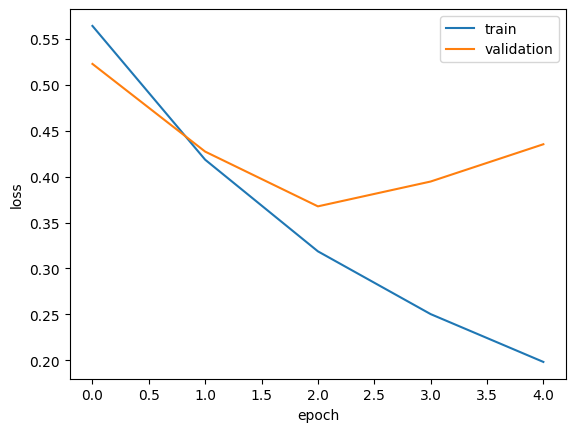

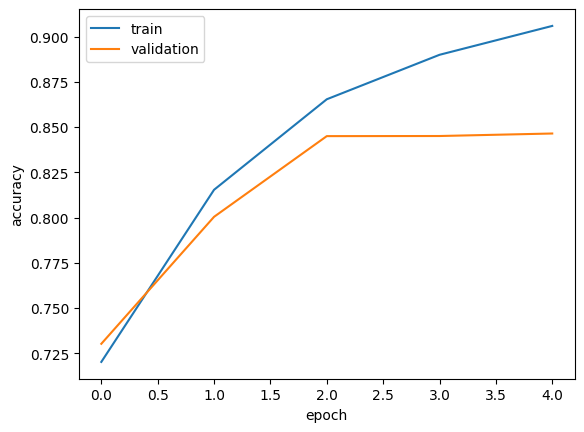

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=10,
    callbacks=[early_stopping],
    sample_weight=sample_weight,
)

# plot training and validation loss per epoch
plt.figure()
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

# plot accuracy per epoch
plt.figure()
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)
model.save(model_dir / "lstm_sentiment.keras")


## Final predictions! (MLP)